In [25]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor

In [26]:
df = pd.read_csv(
    "../Dataset/AirQuality_clean.csv",
    parse_dates=["timestamp"]
).sort_values("timestamp")

df = df.set_index("timestamp")


In [27]:
POLLUTANTS = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
POLLUTANTS = [p for p in POLLUTANTS if p in df.columns]

HORIZONS = [1, 6, 12, 24]

In [28]:
LAGS = [1, 3, 6, 12, 24]

for p in POLLUTANTS:
    for lag in LAGS:
        df[f"{p}_lag{lag}"] = df[p].shift(lag)

# Calendar features
df["hour"] = df.index.hour
df["weekday"] = df.index.dayofweek
df["month"] = df.index.month
df["is_weekend"] = df["weekday"].isin([5, 6]).astype(int)

df = df.dropna()


In [29]:
TARGETS = ['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)']

for col in TARGETS:
    df[f"{col}_lag1"] = df[col].shift(1)
    df[f"{col}_lag6"] = df[col].shift(6)
    df[f"{col}_lag12"] = df[col].shift(12)
    df[f"{col}_lag24"] = df[col].shift(24)
    df[f"{col}_roll24"] = df[col].rolling(24).mean()
    
horizons = [1, 6, 12, 24]  # hours ahead

for h in horizons:
    df[f"CO_t+{h}"] = df["CO(GT)"].shift(-h)
    df[f"NO2_t+{h}"] = df["NO2(GT)"].shift(-h)
    df[f"NOx_t+{h}"] = df["NOx(GT)"].shift(-h)
    df[f"C6H6_t+{h}"] = df["C6H6(GT)"].shift(-h)
    
df = df.ffill().bfill()
df = df.drop(columns=["Unnamed: 15", "Unnamed: 16"], errors='ignore')


In [30]:
models = {
    "LinearRegression": LinearRegression(),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}


In [31]:
results = []

FEATURES = (
    df.select_dtypes(include=[np.number])
      .columns
)

for pollutant in POLLUTANTS:
    for h in HORIZONS:

        df_h = df.copy()
        df_h["target"] = df_h[pollutant].shift(-h)
        df_h = df_h.dropna()

        # --- SAFE numeric-only feature selection ---
        FEATURES = (
            df_h.select_dtypes(include=[np.number])
                .columns
                .difference(POLLUTANTS + ["target"])
        )

        X = df_h[FEATURES]
        y = df_h["target"]


        # Time-aware split
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, shuffle=False
        )

        # Scaling (needed for Linear Regression)
        scaler = RobustScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled  = scaler.transform(X_test)

        for name, model in models.items():

            if name == "LinearRegression":
                model.fit(X_train_scaled, y_train)
                y_pred = model.predict(X_test_scaled)
            else:
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            r2 = r2_score(y_test, y_pred)
            mae = mean_absolute_error(y_test, y_pred)

            results.append({
                "pollutant": pollutant,
                "horizon": h,
                "model": name,
                "R2": r2,
                "MAE": mae,
                "RMSE": rmse
            })

            print(
                f"{pollutant:8s} | {h:2d}h | {name:15s} "
                f"→ R²={r2:.3f}, MAE={mae:.3f}, RMSE: {rmse:.4f}"
            )


CO(GT)   |  1h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
CO(GT)   |  1h | XGBoost         → R²=0.998, MAE=0.037, RMSE: 0.0546
CO(GT)   |  6h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
CO(GT)   |  6h | XGBoost         → R²=0.998, MAE=0.048, RMSE: 0.0686
CO(GT)   | 12h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
CO(GT)   | 12h | XGBoost         → R²=0.999, MAE=0.030, RMSE: 0.0502
CO(GT)   | 24h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
CO(GT)   | 24h | XGBoost         → R²=0.999, MAE=0.013, RMSE: 0.0357
C6H6(GT) |  1h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
C6H6(GT) |  1h | XGBoost         → R²=0.998, MAE=0.175, RMSE: 0.2806
C6H6(GT) |  6h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
C6H6(GT) |  6h | XGBoost         → R²=0.998, MAE=0.187, RMSE: 0.2794
C6H6(GT) | 12h | LinearRegression → R²=1.000, MAE=0.000, RMSE: 0.0000
C6H6(GT) | 12h | XGBoost         → R²=0.998, MAE=0.184, RMSE: 0.3164
C6H6(GT) | 24h | LinearRegr

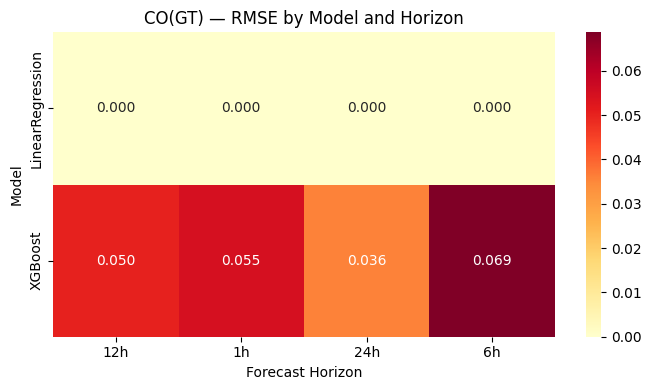

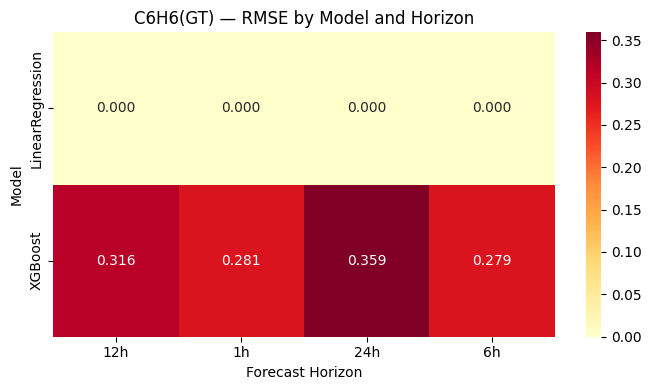

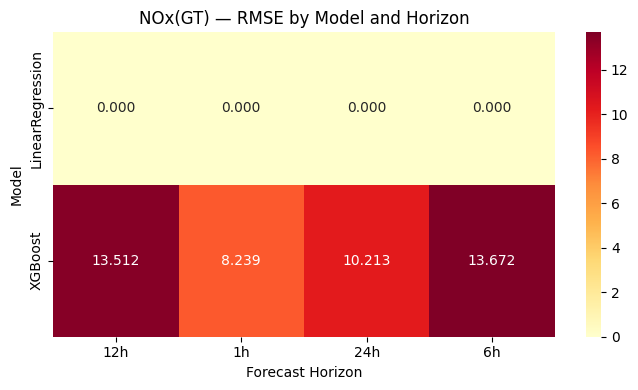

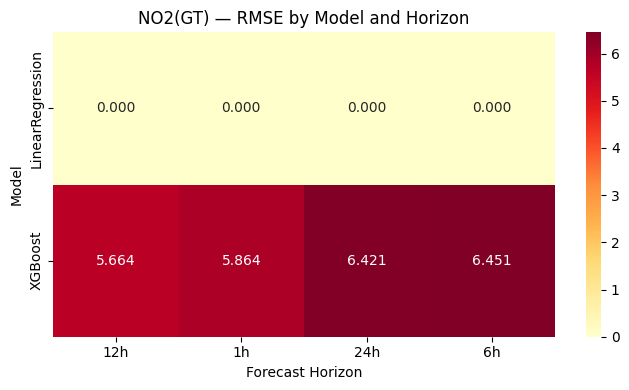

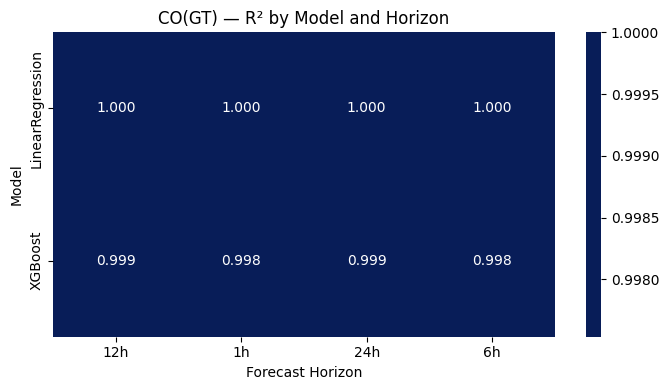

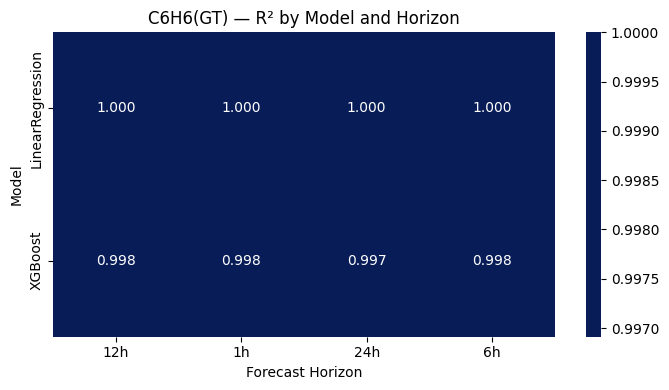

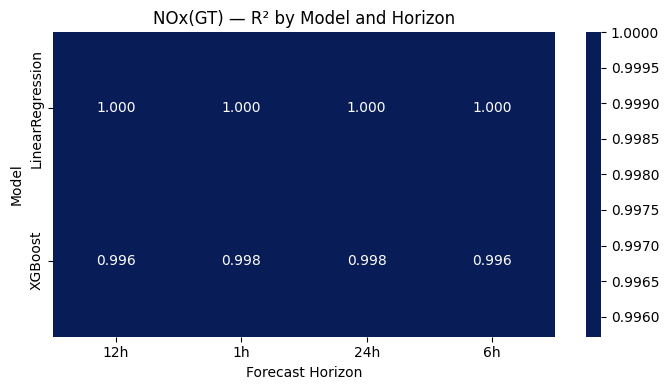

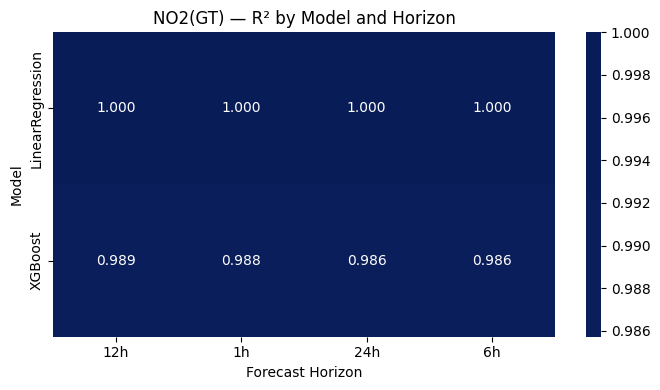

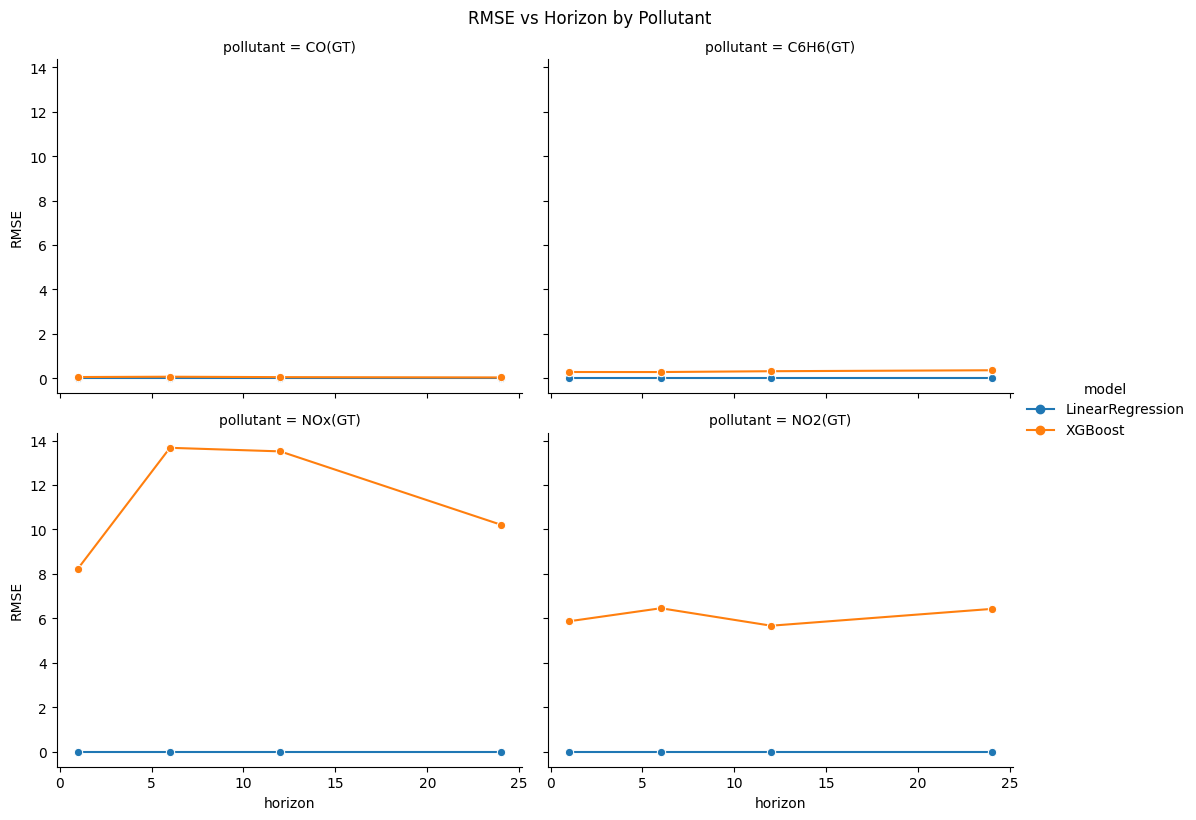

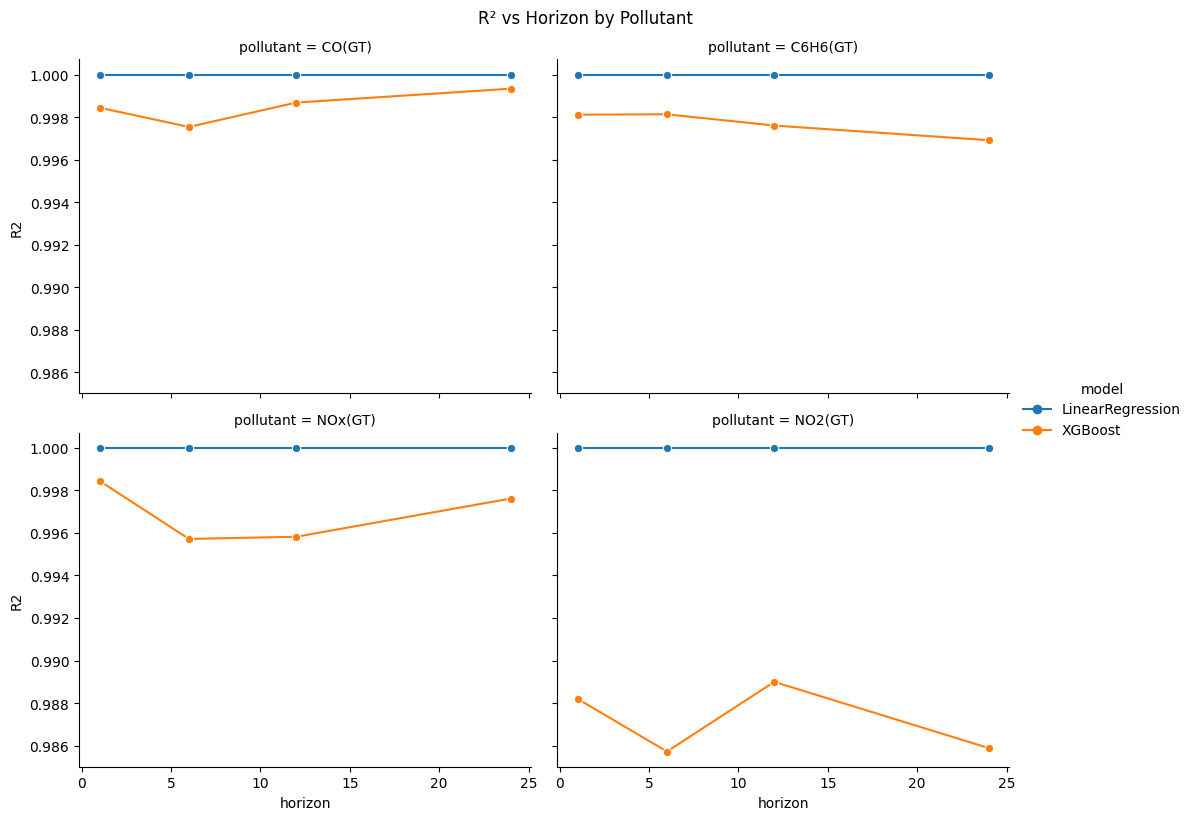

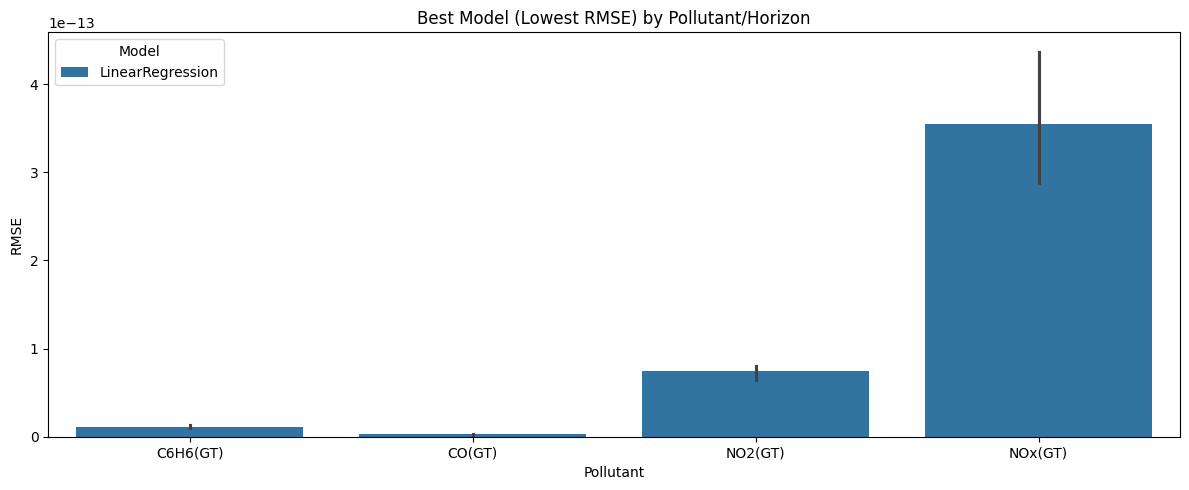

In [ ]:
# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Nice labels for horizon
results_df["h_label"] = results_df["horizon"].astype(str) + "h"

# ---------- 1) Heatmap: RMSE ----------
for p in results_df["pollutant"].unique():
    pivot_rmse = (
        results_df[results_df["pollutant"] == p]
        .pivot(index="model", columns="h_label", values="RMSE")
    )

    plt.figure(figsize=(7, 4))
    sns.heatmap(pivot_rmse, annot=True, fmt=".3f", cmap="YlOrRd")
    plt.title(f"{p} — RMSE by Model and Horizon")
    plt.xlabel("Forecast Horizon")
    plt.ylabel("Model")
    plt.tight_layout()
    plt.show()

# ---------- 2) Heatmap: R² ----------
for p in results_df["pollutant"].unique():
    pivot_r2 = (
        results_df[results_df["pollutant"] == p]
        .pivot(index="model", columns="h_label", values="R2")
    )

    plt.figure(figsize=(7, 4))
    sns.heatmap(pivot_r2, annot=True, fmt=".3f", cmap="YlGnBu", center=0)
    plt.title(f"{p} — R² by Model and Horizon")
    plt.xlabel("Forecast Horizon")
    plt.ylabel("Model")
    plt.tight_layout()
    plt.show()

# ---------- 3) Line plot: metric vs horizon ----------
g = sns.relplot(
    data=results_df,
    x="horizon",
    y="RMSE",
    hue="model",
    col="pollutant",
    kind="line",
    marker="o",
    col_wrap=2,
    height=4,
    aspect=1.3,
)
g.fig.suptitle("RMSE vs Horizon by Pollutant", y=1.02)
plt.show()

g = sns.relplot(
    data=results_df,
    x="horizon",
    y="R2",
    hue="model",
    col="pollutant",
    kind="line",
    marker="o",
    col_wrap=2,
    height=4,
    aspect=1.3,
)
g.fig.suptitle("R² vs Horizon by Pollutant", y=1.02)
plt.show()

In [33]:
results_df = pd.DataFrame(results)

pivot = results_df.pivot_table(
    index=["pollutant", "horizon"],
    columns="model",
    values="R2"
)

print(pivot)


model              LinearRegression   XGBoost
pollutant horizon                            
C6H6(GT)  1                     1.0  0.998112
          6                     1.0  0.998130
          12                    1.0  0.997602
          24                    1.0  0.996912
CO(GT)    1                     1.0  0.998441
          6                     1.0  0.997535
          12                    1.0  0.998681
          24                    1.0  0.999334
NO2(GT)   1                     1.0  0.988198
          6                     1.0  0.985721
          12                    1.0  0.988996
          24                    1.0  0.985884
NOx(GT)   1                     1.0  0.998444
          6                     1.0  0.995716
          12                    1.0  0.995819
          24                    1.0  0.997614
